# [예시] 완성 노트북 — 교육·상담 진로 (students.csv)

**이 노트북이 우리 조의 최종 산출물입니다.** 2차시가 끝나면 [파일] → [다운로드] → .ipynb로 받아 우리 조 공유 폴더에 올립니다.

- 한 화면을 같이 보며 **의논해서** 채웁니다. 키보드는 미션마다 바꿔 잡아요.
- 위에서부터 한 칸씩 ▶ 실행합니다. `____`(밑줄 네 개)가 있는 곳은 **직접 채워야** 실행돼요.
- 열 이름은 사이트 [기획]에서 정한 **기준열 · 계산할열 · 통계함수**를 씁니다.
- 막히면: 학습지 → 사이트 [코드] 탭 힌트(빈칸 틀 → 쓸 함수 → 빈칸마다 들어갈 것) → 오류 해독기 → AI 코치
- 코드 셀에는 `#` 주석으로 **왜 그렇게 했는지** 한 줄씩 남겨요.

## 우리 조 기획 (사이트 [기획]에서 정한 것을 옮겨 적기)

| 항목 | 우리 조 |
|---|---|
| 데이터 | students.csv |
| 탐구 질문 | 공부 시간 구간(study_level)별로 최종 성적(final_score)의 평균은 어떻게 다를까? |
| 기준열 (묶는 기준) | study_level |
| 계산할열 | final_score |
| 통계함수 | 평균 mean() |
| 예상 | 공부 시간이 길수록 평균 성적이 높을 것이다. |

---
# [12차시] 데이터 불러오기와 구조 확인
**hint:** `read_csv`, `head()`, `tail()`, `shape`, `columns`, `dtypes`, `info()`

In [1]:
# 0. 준비 (한글 그래프용 도구 설치 포함) — 처음 한 번 실행
!pip install -q koreanize-matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

# 1. 우리 데이터 불러오기 — 파일 이름만 바꿔요 (예: students → health)
url = "https://raw.githubusercontent.com/daradarav86/bigdata/main/data/students.csv"
df = pd.read_csv(url)
display(df.head())

  school   age address  study_level  travel_level school_support activities internet higher_education  freetime  health  absences    score_1  score_2    final_score
0     GP  18.0       U          2           2       yes         no       no    yes         3       3       4.0   0.0  11  11.0
1     GP  17.0       U          2           1        no         no      yes    yes         3       3       2.0   9.0  11  11.0
2     GP  15.0       U          2           1       yes         no      yes    yes         3       3       6.0  12.0  13  12.0
3     GP  15.0       U          3           1        no        yes      yes    yes         2       5       0.0  14.0  14  14.0
4     GP  16.0       U          2           1        no         no       no    yes         3       5       0.0  11.0  13  13.0


In [2]:
# 2. 데이터 구조 확인
display(df.tail(3))     # 마지막 3행
print(df.shape)         # (행 수, 열 수)
print(df.columns)       # 열 이름 — 여기서 복사해서 쓰면 오타가 없어요
print(df.dtypes)        # 열마다 자료형 (int·float = 숫자, object = 글자)
df.info()               # 비어 있지 않은 값의 개수

    school   age address  study_level  travel_level school_support activities internet higher_education  freetime  health  absences    score_1  score_2    final_score
646     MS  18.0       U          2           2        no        yes       no    yes         1       5       6.0  11.0  12   9.0
647     MS  17.0       U          1           2        no         no      yes    yes         4       2       6.0  10.0  10  10.0
648     MS  18.0       R          1           3        no         no      yes    yes         4       5       4.0  10.0  11  11.0
(649, 15)
Index(['school', 'age', 'address', 'study_level', 'travel_level', 'school_support',
       'activities', 'internet', 'higher_education', 'freetime', 'health', 'absences',
       'score_1', 'score_2', 'final_score'],
      dtype='str')
school            str
age           float64
address           str
study_level       int64
travel_level      int64
school_support         str
activities        str
internet          str
higher_education

**메모 (12차시)**
- 한 행의 뜻: 학생 1명의 기록 1건
- 계산할 숫자 열: final_score (float64) / 기준열 후보: study_level, higher_education
- info()를 보면 final_score는 642개만 값이 있어요 → 비어 있는 값 7개

---
# [13차시] 통계 요약
**hint:** `describe()`, `mean()`, `median()`, `max()`, `min()`, `count()`, `value_counts()`

In [3]:
# 1. 계산할열 한눈에 보기
print(df["final_score"].describe())

# 2. 평균과 중앙값 비교
print("평균:", df["final_score"].mean())
print("중앙값:", df["final_score"].median())
print("최댓값:", df["final_score"].max(), "/ 최솟값:", df["final_score"].min())

# 3. 기준열에는 어떤 값이 몇 개씩 있나?
print(df["study_level"].value_counts())

count    642.000000
mean      11.936137
std        3.231181
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: final_score, dtype: float64
평균: 11.93613707165109
중앙값: 12.0
최댓값: 19.0 / 최솟값: 0.0
study_level
2    305
1    212
3     97
4     35
Name: count, dtype: int64


**메모 (13차시)**
- 평균 11.9, 중앙값 12.0 → 거의 같아요. 아주 큰·작은 값에 크게 끌려가지 않았어요.
- describe의 count(642)가 shape의 행 수(649)보다 작아요 → 비어 있는 값이 있다는 뜻
- study_level 2구간이 305명으로 가장 많고, 4구간은 35명뿐이에요.

---
# [14차시] 결측값 확인과 처리
원본 `df`는 그대로 두고, **제거한 표 `df_removed`**와 **대체한 표 `df_filled`**를 따로 만들어 비교합니다.

**hint:** `isnull().sum()`, `dropna()`, `copy()`, `fillna(값)`, `shape` — 이상한 값이 있으면 평균보다 **중앙값**으로 채워요.

In [4]:
# 1. 열별 결측값 개수
print(df.isnull().sum())

# 2. 결측값이 있는 행을 제거한 표
df_removed = df.dropna()

# 3. 계산할열의 결측값을 대체한 표
df_filled = df.copy()
df_filled["final_score"] = df_filled["final_score"].fillna(df["final_score"].median())

# 4. 세 표 비교
print("행 수 — 원본:", df.shape[0], "/ 제거:", df_removed.shape[0], "/ 대체:", df_filled.shape[0])
print("평균 — 원본:", round(df["final_score"].mean(), 2), "/ 제거:", round(df_removed["final_score"].mean(), 2), "/ 대체:", round(df_filled["final_score"].mean(), 2))

school        0
age           3
address       0
study_level     0
travel_level    0
school_support     0
activities    0
internet      0
higher_education        0
freetime      0
health        0
absences      4
score_1            5
score_2            0
final_score            7
dtype: int64
행 수 — 원본: 649 / 제거: 630 / 대체: 649
평균 — 원본: 11.94 / 제거: 11.97 / 대체: 11.94


**메모 (14차시)**
- final_score의 결측값 7개(약 1%). 그런데 제거하면 649행 → 630행: age·absences·score_1에 비어 있는 행까지 함께 지워져요.
- 세 평균이 거의 같아요 → **그대로 두기**를 골랐어요. groupby 평균은 결측값을 자동으로 건너뛰기 때문이에요. (제거한 표로도 17차시에 확인)

---
# [15차시] 새 열 만들기와 그룹별 분석
**hint:** `df["새열"] = df["열1"] - df["열2"]`, `groupby("기준열")["계산할열"].통계함수()` — 합계 `sum` / 평균 `mean` / 개수 `count`

In [5]:
# 1. 새 열 만들기 — 열끼리 + - * / 로 계산
df["G3_change"] = df["final_score"] - df["score_1"]
display(df.head())

  school   age address  study_level  travel_level school_support activities internet higher_education  freetime  health  absences    score_1  score_2    final_score  G3_change
0     GP  18.0       U          2           2       yes         no       no    yes         3       3       4.0   0.0  11  11.0       11.0
1     GP  17.0       U          2           1        no         no      yes    yes         3       3       2.0   9.0  11  11.0        2.0
2     GP  15.0       U          2           1       yes         no      yes    yes         3       3       6.0  12.0  13  12.0        0.0
3     GP  15.0       U          3           1        no        yes      yes    yes         2       5       0.0  14.0  14  14.0        0.0
4     GP  16.0       U          2           1        no         no       no    yes         3       5       0.0  11.0  13  13.0        2.0


In [6]:
# 2. 기준열로 묶어서 합계·개수·평균 비교
print(df.groupby("study_level")["final_score"].sum())     # 합계
print(df.groupby("study_level")["final_score"].count())   # 개수 — 그룹마다 몇 명?

# 3. 우리 질문의 답: 기준열별 계산할열의 통계함수 결과를 result에 저장
result = df.groupby("study_level")["final_score"].mean()
print(result)

study_level
1    2282.0
2    3668.0
3    1256.0
4     457.0
Name: final_score, dtype: float64
study_level
1    210
2    303
3     94
4     35
Name: final_score, dtype: int64
study_level
1    10.866667
2    12.105611
3    13.361702
4    13.057143
Name: final_score, dtype: float64


## [14·15차시] 함수로 만들기
같은 계산을 다른 기준열로도 반복하고 싶을 때 함수로 만들어 다시 불러요. **hint:** `def 함수이름(매개변수):` / `return 값`

In [7]:
def get_group_result(data, group_col):
    out = data.groupby(group_col)["final_score"].mean()
    return out

print(get_group_result(df, "study_level"))     # 우리 기준열
print(get_group_result(df, "higher_education"))    # 다른 기준열로도 불러 보기

study_level
1    10.866667
2    12.105611
3    13.361702
4    13.057143
Name: final_score, dtype: float64
higher_education
no      8.823529
yes    12.304878
Name: final_score, dtype: float64


**메모 (15차시)**
- 새 열 G3_change(마지막 성적 − 첫 성적): 학기 동안 성적이 얼마나 변했는지
- 그룹 크기가 많이 달라서(35명~305명) 합계가 아니라 **평균**으로 비교해요.
- 함수로 higher_education별 평균도 구해 보니 yes 12.3점, no 8.8점이었어요.

---
# [16차시] 그래프
그룹 비교는 **막대 `plt.bar`**, 연도·월처럼 순서가 있으면 **선 `plt.plot`**. x축은 `result.index`, y축은 `result.values` (괄호 없음)

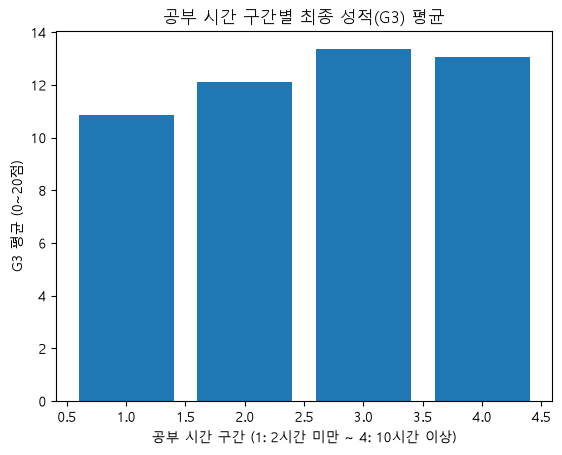

In [8]:
plt.bar(result.index, result.values)
plt.title("공부 시간 구간별 최종 성적(final_score) 평균")
plt.xlabel("공부 시간 구간 (1: 2시간 미만 ~ 4: 10시간 이상)")
plt.ylabel("final_score 평균 (0~20점)")
plt.show()

그래프를 캡처해서(Windows: `Win + Shift + S`) 사이트 [코드] 탭 **‘분석 결과 정리’**의 그래프 칸에 붙여 넣어요.

---
# [17차시] 결과 읽기와 해석
**hint:** 가장 큰 그룹 `idxmax()` · 값 `max()`, 가장 작은 그룹 `idxmin()` · 값 `min()`

In [9]:
print("가장 큰 그룹:", result.idxmax(), round(result.max(), 2))
print("가장 작은 그룹:", result.idxmin(), round(result.min(), 2))
print("차이:", round(result.max() - result.min(), 2), "/ 몇 배:", round(result.max() / result.min(), 2))

# 결측값을 제거한 표로도 결과가 비슷한지 확인
print(df_removed.groupby("study_level")["final_score"].mean())

가장 큰 그룹: 3 13.36
가장 작은 그룹: 1 10.87
차이: 2.5 / 몇 배: 1.23
study_level
1    10.879227
2    12.179054
3    13.358696
4    13.057143
Name: final_score, dtype: float64


### 해석 (사이트 ‘분석 결과 정리’와 발표 5장에 옮겨요)
① **사실**: 공부 시간 구간별 final_score 평균은 구간 3(5~10시간)이 13.36점으로 가장 높고, 구간 1(2시간 미만)이 10.87점으로 가장 낮았다.
② **비교**: 두 집단의 차이는 약 2.5점으로, 약 1.23배였다.
③ **의미**: 공부 시간과 최종 성적은 함께 움직이는 경향이 있다. 다만 가장 오래 공부하는 구간 4(13.06점)는 구간 3보다 조금 낮았다.

**한계**: 구간 4는 35명뿐이고 평균만 비교했으므로, 공부 시간이 성적의 원인이라고 단정할 수 없다.

**진로 연결**: 교사·상담교사가 학생에게 공부 시간 목표를 제안할 때 참고할 수 있다. 다만 ‘무조건 오래’보다 꾸준한 공부 시간을 함께 이야기해야 한다.

## 제출 전 체크리스트 (12~17차시 필수 도구)
- [ ] [12] head/tail, shape, columns, dtypes, info()
- [ ] [13] describe(), 평균·중앙값 비교, value_counts()
- [ ] [14] isnull().sum(), df_removed와 df_filled 비교, 고른 방법과 이유
- [ ] [15] 새 열 1개, groupby로 sum·count·평균 비교
- [ ] [14·15] 함수(def, return)를 만들어 두 번 이상 불렀다
- [ ] [16] 제목·축 이름이 있는 그래프 1개
- [ ] [17] 가장 큰·작은 그룹과 차이, 해석 ①②③ + 한계
- [ ] 사이트 ‘분석 결과 정리’에 숫자·그래프·해석을 옮겼다
- [ ] [파일] → [다운로드] → .ipynb → 우리 조 공유 폴더에 올렸다

## 막히면?
| 증상 | 확인할 것 |
|---|---|
| `KeyError: '열이름'` | 열 이름 오타. `print(df.columns)`에서 복사해 붙여 넣기 |
| `NameError` | 위 셀을 먼저 실행했는지 (특히 0. 준비 셀, result를 만드는 셀) |
| 결과가 `NaN`이거나 비어 있음 | 계산할열이 숫자 열인지(`df.dtypes`), 결측값이 너무 많지 않은지(`isnull().sum()`) |
| 그래프 한글이 □로 깨짐 | 0. 준비 셀을 실행했는지. 그래도 깨지면 [런타임] → [세션 다시 시작] 후 처음부터 |
| 막대가 너무 많음 | `result.head(10)`으로 앞 10개만 그리기 |